# M6 — Monthly Median Composites with QA

This notebook orchestrates the full retrieval pipeline for the Wadi Gaza study.
For each **site** and each monthly **window** it builds a cloud-masked **median
composite** (reflectance bands + vegetation indices) and records the **QA
metrics** the PI asked to track.

**Per composite it produces:**
- a median composite of the requested bands + indices (`reduce="median"`), with
  clouds/shadows dropped per pixel via the **SCL** mask *before* the median;
- a QA row: number of scenes used, mean scene cloud %, % no-data pixels, and the
  mean per-pixel temporal standard deviation (a composite-stability measure).

**Approach decided with the PI:**
- Values come back as **surface reflectance in 0–1** — Sentinel Hub already
  applies the ÷10,000 scaling, so no manual rescaling is needed.
- Indices are computed **per scene, then medianed per pixel** (median-of-indices).
- SCL classes treated as unusable: `s2grab.evalscripts.DEFAULT_SCL_MASK`
  = (0, 1, 3, 8, 9, 10, 11). *(pending PI confirmation)*
- SAVI uses L = 0.428 with the standard ×(1+L) form.

Run the cells top to bottom.

In [1]:
import sys, os
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from rasterio.transform import from_bounds
from rasterio.features import geometry_mask

# Make the s2grab package importable whether we run from the repo root or notebooks/.
ROOT = Path.cwd()
if not (ROOT / "s2grab").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))

from s2grab import S2Client, aoi_from_bounds, make_evalscript, month_windows
from s2grab.sites import load_aois

client = S2Client()
print("s2grab ready. repo root:", ROOT)

s2grab ready. repo root: /home/tshihadah/code/wadi-gaza-research


/home/tshihadah/code/wadi-gaza-research/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 1 · Parameters

Everything you'd normally change lives here.

`DEMO = True` runs a tiny, fast job (one clear-sky farmland AOI near Yuma, AZ,
for a single month) so you can validate the pipeline end-to-end. Flip it to
`False` to run the real study configuration against the site polygons.

In [2]:
# --- What to run -------------------------------------------------------------
DEMO = True   # True: tiny fast validation run; False: full study configuration

# --- Sites (used when DEMO is False) -----------------------------------------
SITES_SOURCE = ROOT / "sites" / "Cities_SS4A" / "Cities_SS4A.shp"
ID_FIELD = "CITY_NAME"      # attribute used to name each site
CLIP_TO_POLYGON = True      # mask output to each site's polygon

# --- Temporal windows --------------------------------------------------------
MONTHS = [9, 11, 1, 5]                 # Sep, Nov, Jan, May
YEARS = list(range(2019, 2025))        # 2019–2024

# --- Product -----------------------------------------------------------------
BANDS = ["B02", "B03", "B04", "B05", "B08", "B8A", "B11", "B12"]
INDICES = ["NDVI", "GNDVI", "SAVI", "NDRE"]
RESOLUTION = 10             # metres (common output grid for all bands)
UPSAMPLING = "NEAREST"      # how 20 m bands (B05, B8A, B11, B12) & NDRE are
                            # resampled onto the 10 m grid: "NEAREST" keeps exact
                            # values (blocky); "BILINEAR" is smoother but interpolates

# --- Filtering / masking -----------------------------------------------------
MAX_CLOUD = 10              # scene-level cloud filter (%); PI prefers 5, up to 10
MASK_SCL = True             # per-pixel SCL cloud/shadow masking before compositing

# --- QA / output -------------------------------------------------------------
COMPUTE_STD = True          # also fetch a std composite for the stability metric
OUT_DIR = ROOT / "outputs" / "composites"

# --- Demo overrides ----------------------------------------------------------
if DEMO:
    MONTHS = [6]
    YEARS = [2024]
    OUT_DIR = ROOT / "outputs" / "_demo_composites"

print("DEMO:", DEMO)
print("windows:", [(y, m) for y in YEARS for m in MONTHS])
print("product bands:", BANDS, "+ indices:", INDICES)
print("upsampling:", UPSAMPLING)
print("output dir:", OUT_DIR)

DEMO: True
windows: [(2024, 6)]
product bands: ['B02', 'B03', 'B04', 'B05', 'B08', 'B8A', 'B11', 'B12'] + indices: ['NDVI', 'GNDVI', 'SAVI', 'NDRE']
upsampling: NEAREST
output dir: /home/tshihadah/code/wadi-gaza-research/outputs/_demo_composites


## 2 · Load areas of interest

In demo mode we use a single rectangular AOI. Otherwise we load every site
polygon from the shapefile via `load_aois`, which reprojects each to its local
UTM zone and (optionally) keeps the polygon for clipping.

In [3]:
if DEMO:
    aois = {
        "Yuma_demo": aoi_from_bounds(-114.63, 32.70, -114.60, 32.72, resolution=RESOLUTION)
    }
else:
    aois = load_aois(
        SITES_SOURCE,
        id_field=ID_FIELD,
        resolution=RESOLUTION,
        clip=CLIP_TO_POLYGON,
    )

print(f"{len(aois)} site(s) loaded")
for name, aoi in list(aois.items())[:5]:
    print(f"  {name}: {aoi}")

1 site(s) loaded
  Yuma_demo: AOI(EPSG:32611, 286x228px, 10.0m, bbox)


## 3 · Build the monthly windows

Each (year, month) pair becomes a calendar-month date range
`(YYYY-MM-01, YYYY-MM-DD)`. Scenes inside that range that pass the cloud filter
feed the composite.

In [4]:
windows = month_windows(YEARS, MONTHS)
pd.DataFrame(windows)

,label,year,month,start,end
0,2024-06,2024,6,2024-06-01,2024-06-30


## 4 · QA helpers

Two small functions:

- `study_area_mask(aoi, shape)` — a boolean mask of pixels *inside the study
  area*. For a clipped (polygon) AOI it rasterizes the polygon so pixels outside
  it are excluded from the no-data denominator; for a plain bbox AOI every pixel
  counts.
- `composite_qa(...)` — searches, fetches the median composite (and optionally a
  std composite), then computes the QA metrics over the study-area pixels.

In [ ]:
def study_area_mask(aoi, shape: tuple[int, int]) -> np.ndarray:
    """Boolean (H, W) mask: True for pixels inside the study area.

    Clipped AOIs -> the polygon footprint; bbox AOIs -> everything.
    """
    height, width = shape
    if not aoi.is_clipped:
        return np.ones((height, width), dtype=bool)
    transform = from_bounds(*aoi.bbox, width=width, height=height)
    # invert=True -> True inside the geometry.
    return geometry_mask(
        [aoi.geometry.geometry],
        out_shape=(height, width),
        transform=transform,
        invert=True,
    )


def composite_qa(client, aoi, start, end, *, bands, indices,
                 max_cloud, mask_scl, compute_std, upsampling=None):
    """Fetch a masked median composite + QA for one AOI/window.

    Returns (image, qa) where image is None when no data qualifies.
    """
    scenes = client.search(aoi, start, end, max_cloud=max_cloud)
    n_scenes = len(scenes)
    clouds = [s.cloud_cover for s in scenes if s.cloud_cover is not None]
    mean_cloud = float(np.mean(clouds)) if clouds else float("nan")

    qa = {"n_scenes": n_scenes, "mean_cloud": mean_cloud,
          "pct_nodata": float("nan"), "mean_pixel_std": float("nan")}

    if n_scenes == 0:
        return None, qa

    median_prod = make_evalscript(bands=bands, indices=indices,
                                  reduce="median", mask_scl=mask_scl)
    image = client.fetch(aoi, start=start, end=end,
                         product=median_prod, max_cloud=max_cloud,
                         upsampling=upsampling)
    if image is None:
        return None, qa

    arr = image.array                              # (H, W, nbands)
    mask = study_area_mask(aoi, arr.shape[:2])     # (H, W)
    study_px = int(mask.sum())

    # A pixel is "no data" when every band is NaN (no valid observation).
    nodata = np.all(np.isnan(arr), axis=2) & mask
    qa["pct_nodata"] = 100.0 * nodata.sum() / study_px if study_px else float("nan")

    if compute_std:
        std_prod = make_evalscript(bands=bands, indices=indices,
                                   reduce="std", mask_scl=mask_scl)
        std_img = client.fetch(aoi, start=start, end=end,
                               product=std_prod, max_cloud=max_cloud,
                               upsampling=upsampling)
        if std_img is not None:
            qa["mean_pixel_std"] = float(np.nanmean(std_img.array[mask]))

    return image, qa

## 5 · Run the pipeline

For every site × window: search, composite, compute QA, and save a GeoTIFF.
Results are collected into a **manifest**. Failures (no scenes / no data) are
recorded rather than raised, so one bad window doesn't stop the run.

In [6]:
EMPTY_QA = {"n_scenes": None, "mean_cloud": None,
            "pct_nodata": None, "mean_pixel_std": None}

records = []
for site, aoi in aois.items():
    for w in windows:
        try:
            image, qa = composite_qa(
                client, aoi, w["start"], w["end"],
                bands=BANDS, indices=INDICES,
                max_cloud=MAX_CLOUD, mask_scl=MASK_SCL, compute_std=COMPUTE_STD,
                upsampling=UPSAMPLING,
            )
        except Exception as exc:  # keep the run going; log the failure
            records.append({"site": site, "window": w["label"],
                            "status": f"error: {exc}", "path": None, **EMPTY_QA})
            print(f"{site} {w['label']}: ERROR {exc}")
            continue

        if image is None:
            records.append({"site": site, "window": w["label"],
                            "status": "no data", "path": None, **qa})
            print(f"{site} {w['label']}: no data ({qa['n_scenes']} scenes)")
            continue

        path = OUT_DIR / site / f"{site}_{w['label']}.tif"
        image.save(path)
        records.append({"site": site, "window": w["label"], "status": "ok",
                        "path": str(path.relative_to(ROOT)), **qa})
        print(f"{site} {w['label']}: {qa['n_scenes']} scenes, "
              f"{qa['pct_nodata']:.1f}% no-data -> {path.name}")

manifest = pd.DataFrame(records)
print(f"\n{len(manifest)} composite(s) attempted")

Yuma_demo 2024-06: 8 scenes, 0.0% no-data -> Yuma_demo_2024-06.tif

1 composite(s) attempted


## 6 · QA manifest

One row per composite, with the metrics the PI asked to track, saved as a CSV
alongside the rasters for the study record.

In [7]:
cols = ["site", "window", "status", "n_scenes", "mean_cloud",
        "pct_nodata", "mean_pixel_std", "path"]
manifest = manifest.reindex(columns=cols)

manifest_path = OUT_DIR / "qa_manifest.csv"
manifest_path.parent.mkdir(parents=True, exist_ok=True)
manifest.to_csv(manifest_path, index=False)
print("manifest ->", manifest_path.relative_to(ROOT))
manifest

manifest -> outputs/_demo_composites/qa_manifest.csv


,site,window,status,n_scenes,mean_cloud,pct_nodata,mean_pixel_std,path
0,Yuma_demo,2024-06,ok,8,1.07375,0.0,0.020757,outputs/_demo_composites/Yuma_demo/Yuma_demo_2...


## 7 · Preview a composite

Quick look at the first successful composite: a true-colour RGB (from the
B04/B03/B02 bands) next to the NDVI layer. No-data pixels appear blank.

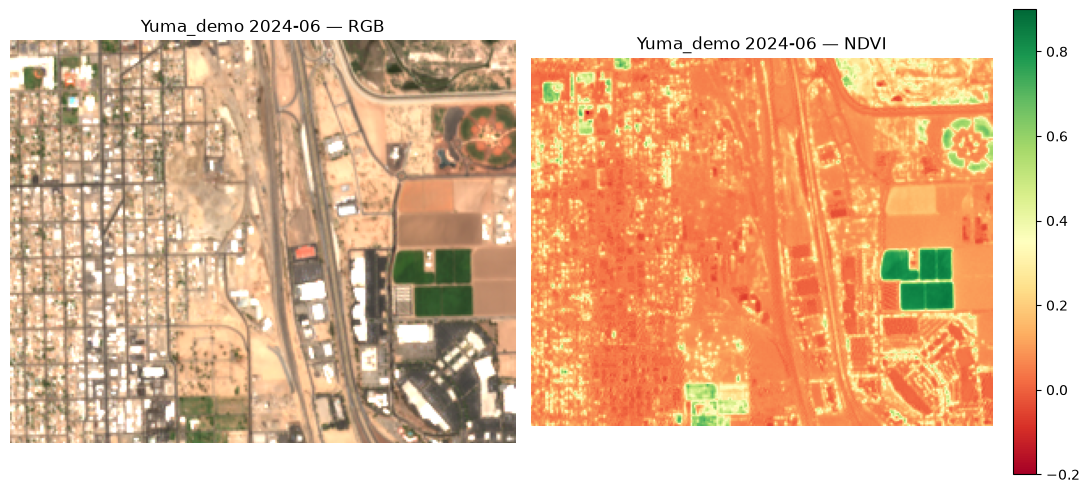

In [8]:
import rasterio

band_names = BANDS + INDICES
ok = manifest[manifest["status"] == "ok"]

if ok.empty:
    print("No successful composite to preview.")
else:
    row = ok.iloc[0]
    with rasterio.open(ROOT / row["path"]) as src:
        stack = np.transpose(src.read(), (1, 2, 0))  # (H, W, bands)

    def band(name):
        return stack[:, :, band_names.index(name)]

    rgb = np.clip(np.dstack([band("B04"), band("B03"), band("B02")]) / 0.3, 0, 1)

    fig, axes = plt.subplots(1, 2, figsize=(11, 5))
    axes[0].imshow(rgb)
    axes[0].set_title(f"{row['site']} {row['window']} — RGB")
    im = axes[1].imshow(band("NDVI"), cmap="RdYlGn", vmin=-0.2, vmax=0.9)
    axes[1].set_title(f"{row['site']} {row['window']} — NDVI")
    fig.colorbar(im, ax=axes[1], fraction=0.046, pad=0.04)
    for ax in axes:
        ax.axis("off")
    plt.tight_layout()
    plt.show()

## 8 · Notes & next steps

- **Scaling:** bands are surface reflectance (0–1); no ÷10,000 applied (Sentinel
  Hub already scales). SAVI uses L = 0.428 with the standard ×(1+L) form.
- **Cloud masking:** SCL classes (0, 1, 3, 8, 9, 10, 11) are dropped per pixel
  before the median. Confirm this class set with the PI.
- **Resolution / resampling:** everything is delivered on a common **10 m** grid.
  The 10 m bands are B02, B03, B04, B08; the **20 m** bands (B05, B8A, B11, B12)
  and **NDRE** (built from B8A + B05) are **upsampled** from their native 20 m to
  10 m server-side — this aligns/stacks the layers (as the PI's land-cover step
  requires) but adds no real detail, so NDRE/SWIR carry 20 m information content.
  The resampling method is set explicitly via `UPSAMPLING` (default `"NEAREST"`,
  which preserves exact values; `"BILINEAR"` is smoother but interpolates).
- **QA captured:** scenes used, mean scene cloud %, % no-data (within the study
  polygon), and mean per-pixel temporal std (composite stability).
- **To scale up:** set `DEMO = False` to run the full site × window matrix. That
  is a large job (many sites × 24 windows × up to 2 requests each) — consider
  running a subset of sites first.
- **Possible additions:** persist per-band std rasters and the SCL layer for the
  record; polygon-level summary statistics (Statistical API); and, per the PI,
  computing NDVI-only for non–Wadi Gaza sites to save time.
